# CNN

In [30]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Dropout, BatchNormalization,
    Conv2D, MaxPooling2D, Flatten
)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.metrics import confusion_matrix, classification_report

import joblib

In [ ]:
#(x_train, y_train), (x_test, y_test) = cifar10.load_data()  --> takes too long to download

# https://data.brainchip.com/dataset-mirror/cifar10/   --> download from here and extract it in your code folder and run the below code cell 

In [15]:
import pickle
import os
import numpy as np

cifar_path = r"cifar-10-batches-py"

def load_batch(file_path):
    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")

    X = batch[b"data"]
    y = batch[b"labels"]

    return X, y

x_train_list = []
y_train_list = []

for i in range(1, 6):
    X, y = load_batch(
        os.path.join(cifar_path, f"data_batch_{i}")
    )

    x_train_list.append(X)
    y_train_list.extend(y)

x_train = np.concatenate(x_train_list)
y_train = np.array(y_train_list).reshape(-1, 1)

x_test, y_test = load_batch(
    os.path.join(cifar_path, "test_batch")
)

y_test = np.array(y_test).reshape(-1, 1)

x_train = x_train.reshape(-1, 3, 32, 32)
x_train = x_train.transpose(0, 2, 3, 1)

x_test = x_test.reshape(-1, 3, 32, 32)
x_test = x_test.transpose(0, 2, 3, 1)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test :", x_test.shape)
print("y_test :", y_test.shape)

x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test : (10000, 32, 32, 3)
y_test : (10000, 1)


In [16]:
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

print("Number of Training Images:", x_train.shape[0])
print("Number of Testing Images:", x_test.shape[0])

print("First Image:")
print(x_train[0])

Training Data Shape: (50000, 32, 32, 3)
Testing Data Shape: (10000, 32, 32, 3)
Number of Training Images: 50000
Number of Testing Images: 10000
First Image:
[[[0.23137255 0.24313726 0.24705882]
  [0.16862746 0.18039216 0.1764706 ]
  [0.19607843 0.1882353  0.16862746]
  ...
  [0.61960787 0.5176471  0.42352942]
  [0.59607846 0.49019608 0.4       ]
  [0.5803922  0.4862745  0.40392157]]

 [[0.0627451  0.07843138 0.07843138]
  [0.         0.         0.        ]
  [0.07058824 0.03137255 0.        ]
  ...
  [0.48235294 0.34509805 0.21568628]
  [0.46666667 0.3254902  0.19607843]
  [0.47843137 0.34117648 0.22352941]]

 [[0.09803922 0.09411765 0.08235294]
  [0.0627451  0.02745098 0.        ]
  [0.19215687 0.10588235 0.03137255]
  ...
  [0.4627451  0.32941177 0.19607843]
  [0.47058824 0.32941177 0.19607843]
  [0.42745098 0.28627452 0.16470589]]

 ...

 [[0.8156863  0.6666667  0.3764706 ]
  [0.7882353  0.6        0.13333334]
  [0.7764706  0.6313726  0.10196079]
  ...
  [0.627451   0.52156866 0.274

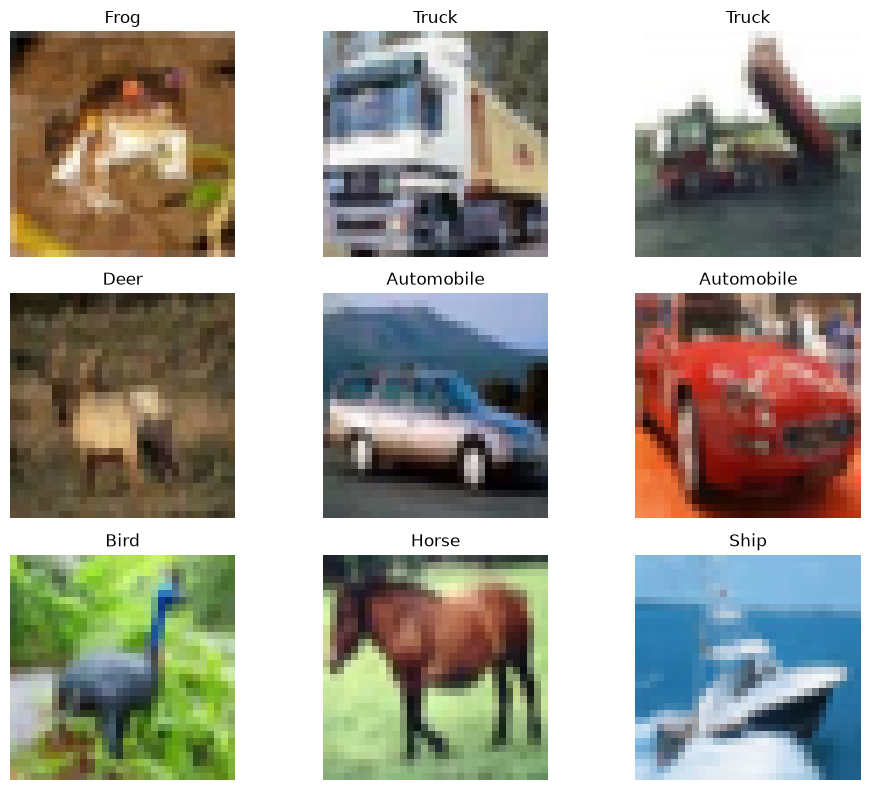

In [17]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

plt.figure(figsize=(10, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [18]:
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

In [19]:
train_norm = x_train.astype('float32')
test_norm = x_test.astype('float32')

train_norm = train_norm / 255.0
test_norm = test_norm / 255.0

In [20]:
model = Sequential()

model.add(keras.Input(shape=(32, 32, 3)))

model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(100, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(10, activation='softmax'))

In [21]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        25,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,070 (328.40 KB)

 Trainable params: 83,550 (326.37 KB)

 Non-trainable params: 520 (2.03 KB)

In [22]:
m2 = model.fit(
    train_norm,
    y_train,
    epochs=10,
    batch_size=25,
    validation_split=0.1
)

Epoch 1/10
1800/1800 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.4842 - loss: 1.4602 - val_accuracy: 0.1200 - val_loss: 6.1847
Epoch 2/10
1800/1800 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.6013 - loss: 1.1368 - val_accuracy: 0.1094 - val_loss: 9.2809
Epoch 3/10
1800/1800 ━━━━━━━━━━━━━━━━━━━━ 33s 19ms/step - accuracy: 0.6495 - loss: 1.0058 - val_accuracy: 0.1774 - val_loss: 3.9832
Epoch 4/10
1800/1800 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.6771 - loss: 0.9216 - val_accuracy: 0.1200 - val_loss: 10.4844
Epoch 5/10
1800/1800 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.7022 - loss: 0.8549 - val_accuracy: 0.1332 - val_loss: 8.0294
Epoch 6/10
1800/1800 ━━━━━━━━━━━━━━━━━━━━ 32s 18ms/step - accuracy: 0.7220 - loss: 0.7982 - val_accuracy: 0.2132 - val_loss: 3.4971
Epoch 7/10
1800/1800 ━━━━━━━━━━━━━━━━━━━━ 32s 18ms/step - accuracy: 0.7414 - loss: 0.7490 - val_accuracy: 0.0958 - val_loss: 21.0377
Epoch 8/10
1800/1800 ━━━━━━━━━━━━━━━━━━━━ 34s 19ms/step - accuracy: 0.7485

In [23]:
test_loss, test_accuracy = model.evaluate(
    test_norm,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.2162 - loss: 6.5489
Test Loss: 6.548858165740967
Test Accuracy: 0.21619999408721924


In [24]:
pred = model.predict(test_norm)

print("First Prediction:", pred[0])

print("Predicted Class:", np.argmax(pred[0]))

print("Actual Class:", np.argmax(y_test[0]))

print("Predicted Label:", class_names[np.argmax(pred[0])])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
First Prediction: [1.6185723e-02 8.1828704e-09 2.3078758e-03 3.2054025e-01 2.4676665e-03
 5.7531101e-01 7.2156519e-02 1.1030574e-02 3.2958212e-07 4.5662609e-11]
Predicted Class: 5
Actual Class: 3
Predicted Label: Dog


In [25]:
y_pred = np.argmax(pred, axis=1)
y_actual = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_actual, y_pred)

print("Confusion Matrix:")
print(cm)

print(classification_report(
    y_actual,
    y_pred,
    target_names=class_names
))

Confusion Matrix:
[[ 25   0  95 620  47  18  18 177   0   0]
 [  4   0  13 694  22  26  68 173   0   0]
 [  8   0 134 570  12  19 101 156   0   0]
 [  0   0  16 803   5  29  29 118   0   0]
 [  2   0  57 604  61   2  98 176   0   0]
 [  0   0  29 634   5 165  22 145   0   0]
 [  1   0  14 436   3   7 464  75   0   0]
 [  1   0   5 422  11  28  23 510   0   0]
 [  4   0  84 646  23  19  18 206   0   0]
 [  2   0  18 544   4  86  44 302   0   0]]
              precision    recall  f1-score   support

    Airplane       0.53      0.03      0.05      1000
  Automobile       0.00      0.00      0.00      1000
        Bird       0.29      0.13      0.18      1000
         Cat       0.13      0.80      0.23      1000
        Deer       0.32      0.06      0.10      1000
         Dog       0.41      0.17      0.24      1000
        Frog       0.52      0.46      0.49      1000
       Horse       0.25      0.51      0.34      1000
        Ship       0.00      0.00      0.00      1000
       Tru

c:\My Files\LTM-LAB\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\My Files\LTM-LAB\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\My Files\LTM-LAB\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [26]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        25,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 251,172 (981.14 KB)

 Trainable params: 83,550 (326.37 KB)

 Non-trainable params: 520 (2.03 KB)

 Optimizer params: 167,102 (652.75 KB)

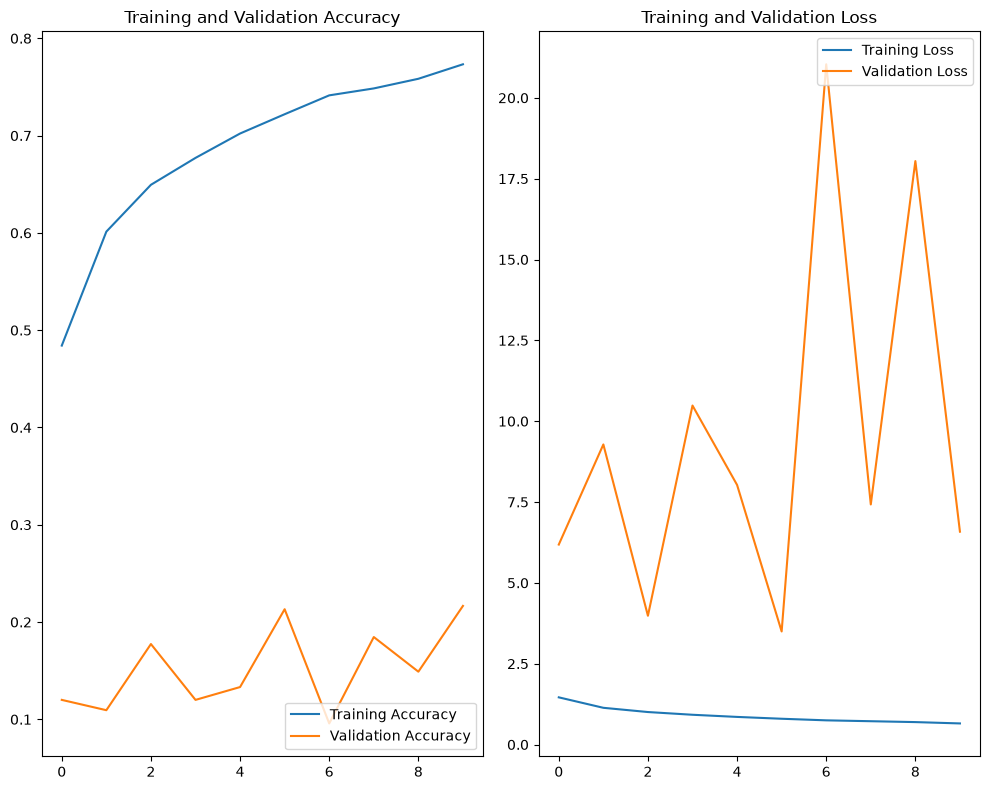

In [27]:
acc = m2.history['accuracy']
val_acc = m2.history['val_accuracy']

loss = m2.history['loss']
val_loss = m2.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(10, 8))

plt.subplot(1, 2, 1)

plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')

plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)

plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')

plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.tight_layout()
plt.savefig('./cifar10_training.png')
plt.show()

In [ ]:
joblib.dump(model,'cnn_model.joblib')

['cnn_model.joblib']

In [31]:
try:
    model = joblib.load("cifar10_model.joblib")
except:
    pass

img = load_img(
    'car.jpg',
    color_mode='rgb',
    target_size=(32, 32)
)

img = img_to_array(img)

img = img.astype('float32')
img = img / 255.0

img = img.reshape(1, 32, 32, 3)

pred_image = model.predict(img)

print("Predicted Class:", class_names[np.argmax(pred_image)])
print("Confidence:", np.max(pred_image))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
Predicted Class: Automobile
Confidence: 1.0
